In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)



# Generate a synthetic dataset with three classes

dataset_configs = {
    "Easy": 1.4,
    "Moderate": 2.5,
    "Difficult": 3.5
}

datasets = {}

for difficulty, std in dataset_configs.items():

    X, y = make_blobs(
        n_samples=400,
        centers=[
            (1, 1),
            (6, 6)
        ],
        cluster_std=std,
        random_state=42
    )
    datasets[difficulty] = (X, y)

# Display the first 10 observations

X, y = datasets["Easy"]

dataset = pd.DataFrame(
    X,
    columns=["X Coordinate", "Y Coordinate"]
)

dataset["Class"] = y

dataset["Class"] = dataset["Class"].map({
    0: "Class A",
    1: "Class B"
})

dataset.head(10)

,X Coordinate,Y Coordinate,Class
0,6.473895,5.418597,Class B
1,5.369908,6.871990,Class B
2,5.268188,7.468613,Class B
3,6.039646,6.041659,Class B
4,4.614553,5.823898,Class B
5,5.947311,7.544623,Class B
6,10.310433,7.567405,Class B
7,1.873768,1.879684,Class A
8,1.292409,-1.743538,Class A
9,-0.185511,-1.120786,Class A


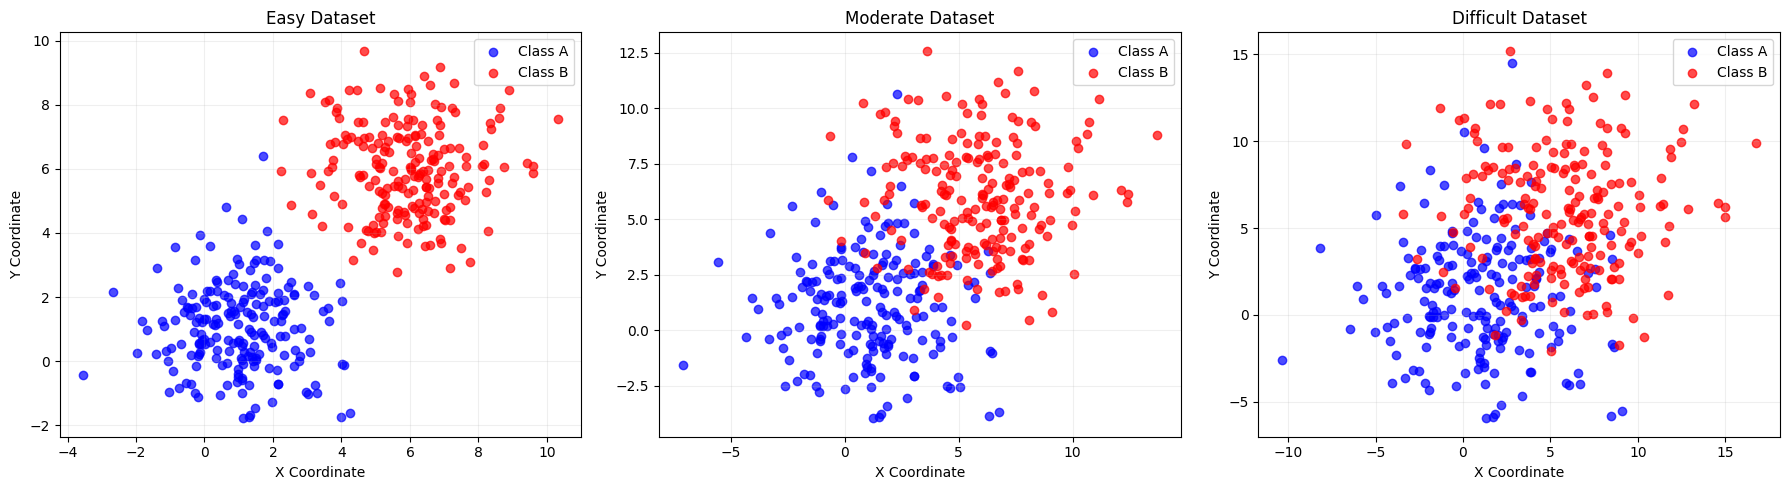

In [32]:
# Visualize datasets with different levels of class overlap

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (difficulty, data) in zip(axes, datasets.items()):

    X, y = data

    ax.scatter(
        X[y == 0, 0],
        X[y == 0, 1],
        color="blue",
        label="Class A",
        alpha=0.7
    )

    ax.scatter(
        X[y == 1, 0],
        X[y == 1, 1],
        color="red",
        label="Class B",
        alpha=0.7
    )

    ax.set_title(f"{difficulty} Dataset")
    ax.set_xlabel("X Coordinate")
    ax.set_ylabel("Y Coordinate")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 300
Testing observations: 100


In [34]:
# Split each dataset into training and testing sets

split_datasets = {}

for difficulty, (X, y) in datasets.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.25,
        random_state=42,
        stratify=y
    )

    split_datasets[difficulty] = (
        X_train,
        X_test,
        y_train,
        y_test
    )

    print(f"{difficulty} Dataset:")
    print(f"Training samples: {len(X_train)}")
    print(f"Testing samples: {len(X_test)}")
    print("-" * 30)

Easy Dataset:
Training samples: 300
Testing samples: 100
------------------------------
Moderate Dataset:
Training samples: 300
Testing samples: 100
------------------------------
Difficult Dataset:
Training samples: 300
Testing samples: 100
------------------------------


In [35]:
# Hyperparameter tuning using GridSearchCV

k_values = [1, 3, 5, 7, 11, 15, 21]

results = []
best_models = {}
cv_results = {}

for difficulty, (X_train, X_test, y_train, y_test) in split_datasets.items():

    # Create a pipeline containing feature scaling and KNN
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ])

    # Define the K values to experiment with
    param_grid = {
        "knn__n_neighbors": k_values
    }

    # Configure GridSearchCV
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=5,
        scoring="accuracy"
    )

    # Train the model and perform cross-validation
    grid_search.fit(X_train, y_train)

    # Store cross-validation results for every K value
    cv_results[difficulty] = pd.DataFrame(
        grid_search.cv_results_
    )

    # Retrieve the best-performing model
    best_model = grid_search.best_estimator_

    best_models[difficulty] = best_model

    # Predict using the untouched test dataset
    predictions = best_model.predict(X_test)

    # Calculate test accuracy
    test_accuracy = accuracy_score(y_test, predictions)

    # Store experimental results
    results.append({
        "Difficulty": difficulty,
        "Best K": grid_search.best_params_["knn__n_neighbors"],
        "CV Accuracy": grid_search.best_score_,
        "Test Accuracy": test_accuracy
    })

    print(f"\n{difficulty} Dataset")
    print(f"Best K: {grid_search.best_params_['knn__n_neighbors']}")
    print(f"Cross-validation Accuracy: {grid_search.best_score_:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print("-" * 35)


Easy Dataset
Best K: 3
Cross-validation Accuracy: 0.9967
Test Accuracy: 1.0000
-----------------------------------

Moderate Dataset
Best K: 3
Cross-validation Accuracy: 0.9167
Test Accuracy: 0.9100
-----------------------------------

Difficult Dataset
Best K: 5
Cross-validation Accuracy: 0.8367
Test Accuracy: 0.8200
-----------------------------------


In [36]:
# Convert experimental results into a DataFrame

results_df = pd.DataFrame(results)

# Convert accuracy scores into percentages

results_df["CV Accuracy (%)"] = (
    results_df["CV Accuracy"] * 100
).round(2)

results_df["Test Accuracy (%)"] = (
    results_df["Test Accuracy"] * 100
).round(2)

# Display experimental results

results_df

,Difficulty,Best K,CV Accuracy,Test Accuracy,CV Accuracy (%),Test Accuracy (%)
0,Easy,3,0.996667,1.00,99.67,100.0
1,Moderate,3,0.916667,0.91,91.67,91.0
2,Difficult,5,0.836667,0.82,83.67,82.0


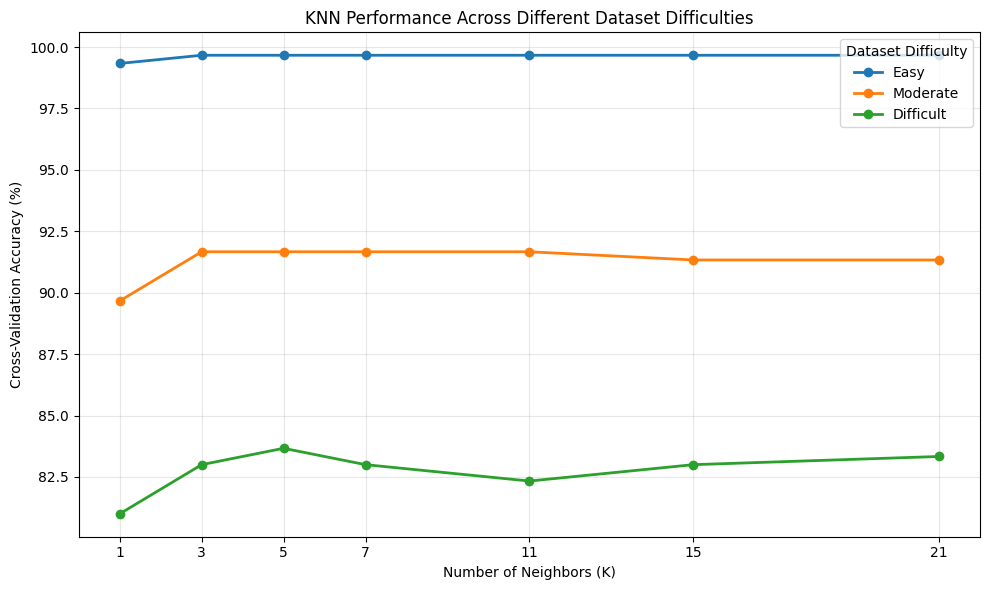

In [37]:
# Compare cross-validation accuracy across different K values

plt.figure(figsize=(10, 6))

for difficulty, cv_df in cv_results.items():

    plt.plot(
        cv_df["param_knn__n_neighbors"].astype(int),
        cv_df["mean_test_score"] * 100,
        marker="o",
        linewidth=2,
        label=difficulty
    )

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Cross-Validation Accuracy (%)")

plt.title("KNN Performance Across Different Dataset Difficulties")

plt.xticks(k_values)
plt.legend(title="Dataset Difficulty")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
# Generate final predictions using the best model for each dataset

final_predictions = {}

for difficulty, (X_train, X_test, y_train, y_test) in split_datasets.items():

    # Retrieve the best model selected by GridSearchCV
    best_model = best_models[difficulty]

    # Generate predictions on the test dataset
    predictions = best_model.predict(X_test)

    # Store predictions for later evaluation
    final_predictions[difficulty] = predictions

    print(f"\n{difficulty} Dataset")
    print(f"Selected K: {best_model.named_steps['knn'].n_neighbors}")
    print(f"Predictions generated: {len(predictions)}")


Easy Dataset
Selected K: 3
Predictions generated: 100

Moderate Dataset
Selected K: 3
Predictions generated: 100

Difficult Dataset
Selected K: 5
Predictions generated: 100


In [39]:
# Generate classification reports for all three datasets

for difficulty, (X_train, X_test, y_train, y_test) in split_datasets.items():

    print(f"\n{'=' * 50}")
    print(f"Classification Report: {difficulty} Dataset")
    print('=' * 50)

    print(
        classification_report(
            y_test,
            final_predictions[difficulty],
            target_names=["Class A", "Class B"]
        )
    )


Classification Report: Easy Dataset
              precision    recall  f1-score   support

     Class A       1.00      1.00      1.00        50
     Class B       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100


Classification Report: Moderate Dataset
              precision    recall  f1-score   support

     Class A       0.87      0.96      0.91        50
     Class B       0.96      0.86      0.91        50

    accuracy                           0.91       100
   macro avg       0.91      0.91      0.91       100
weighted avg       0.91      0.91      0.91       100


Classification Report: Difficult Dataset
              precision    recall  f1-score   support

     Class A       0.80      0.86      0.83        50
     Class B       0.85      0.78      0.81        50

    accuracy                           0.82       100
   macro

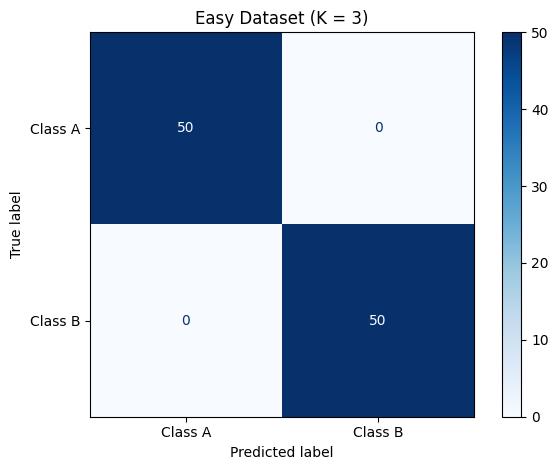

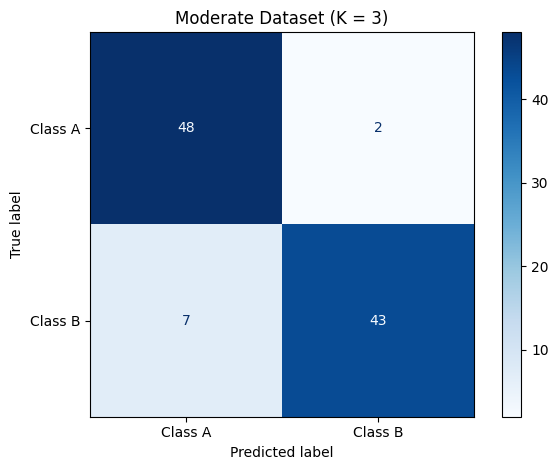

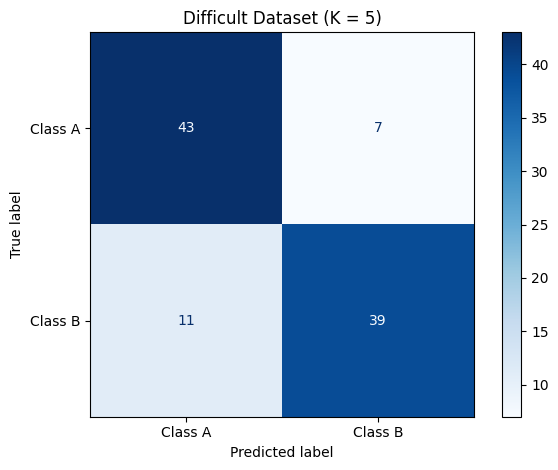

In [40]:
# Generate confusion matrices for all three datasets

for difficulty, (X_train, X_test, y_train, y_test) in split_datasets.items():

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        final_predictions[difficulty]
    )

    # Display confusion matrix
    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Class A", "Class B"]
    )

    # Retrieve the selected K value
    best_k = best_models[difficulty].named_steps["knn"].n_neighbors

    # Plot confusion matrix
    cm_display.plot(cmap="Blues", values_format="d")

    plt.title(f"{difficulty} Dataset (K = {best_k})")
    plt.tight_layout()
    plt.show()

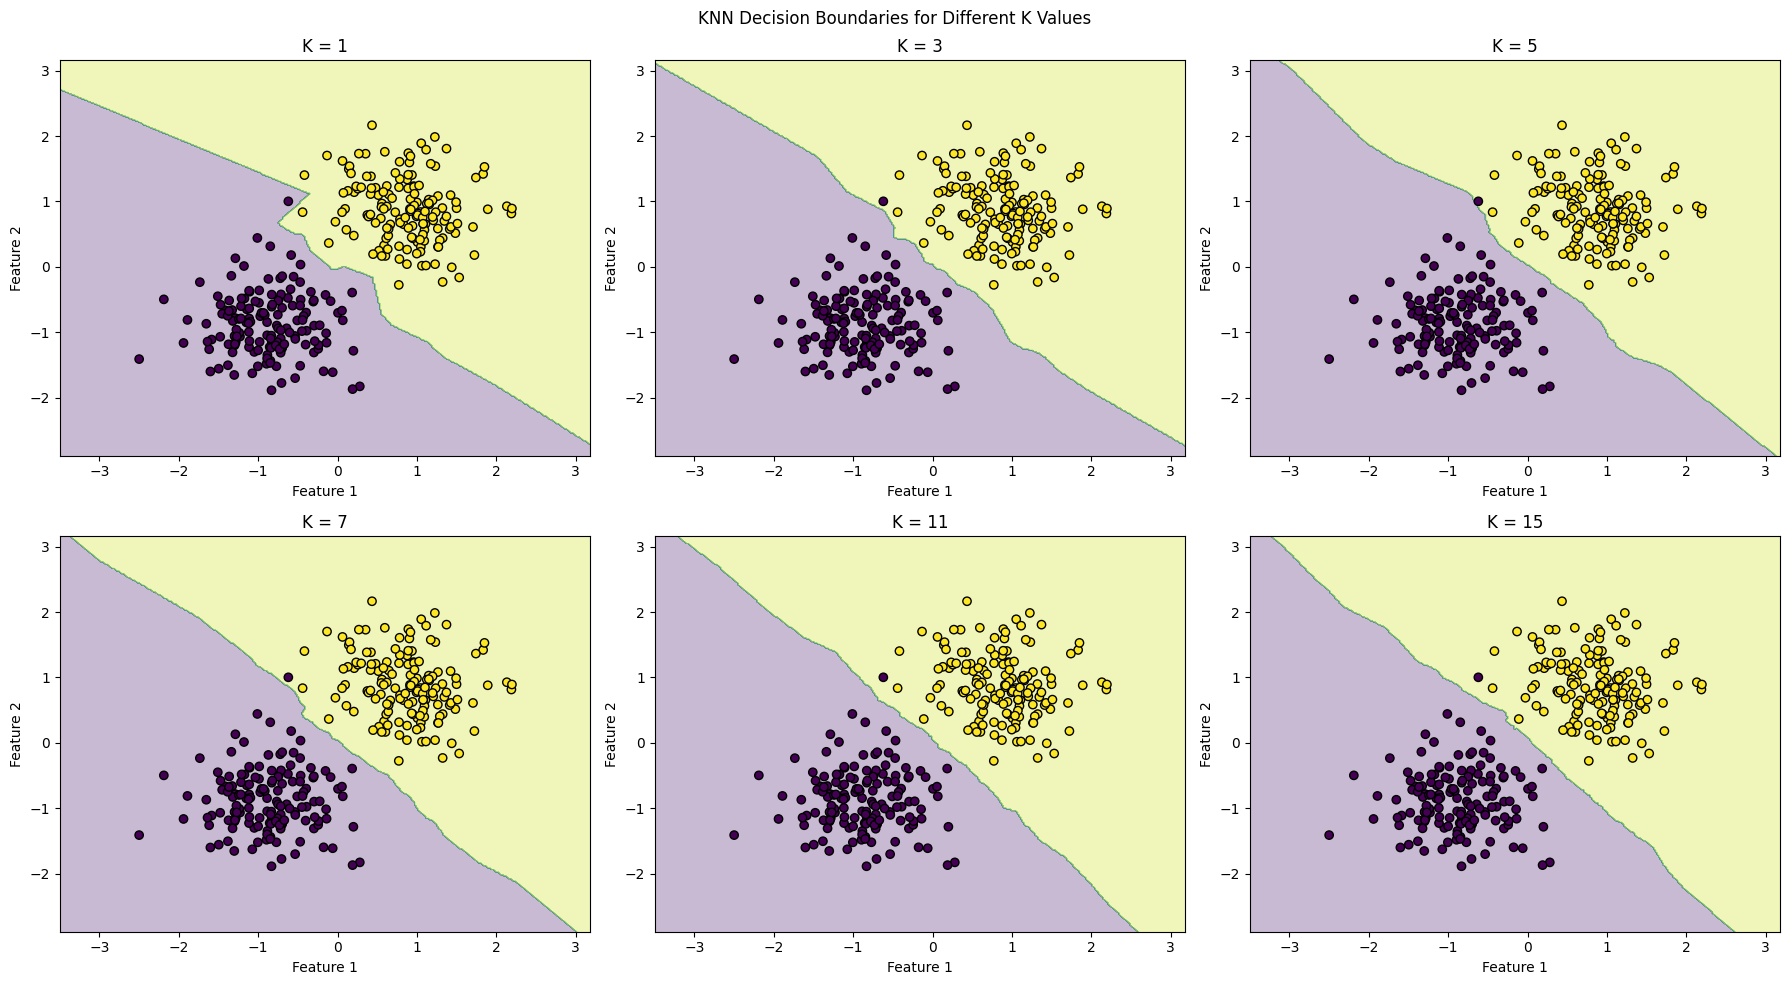

In [41]:
# Create a mesh grid
x_min, x_max = X_train_scaled[:, 0].min() - 1, X_train_scaled[:, 0].max() + 1
y_min, y_max = X_train_scaled[:, 1].min() - 1, X_train_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Plot decision boundaries for different K values
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, k in zip(axes.ravel(), k_values):

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_scaled, y_train)

    Z = model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    )

    Z = Z.reshape(xx.shape)

    ax.contourf(
        xx,
        yy,
        Z,
        alpha=0.3
    )

    ax.scatter(
        X_train_scaled[:, 0],
        X_train_scaled[:, 1],
        c=y_train,
        edgecolors="black"
    )

    ax.set_title(f"K = {k}")

    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.suptitle("KNN Decision Boundaries for Different K Values")

plt.tight_layout()
plt.show()